# ISS Real-Time Data Analytics Platform
**Final Project — Alua Muratova (BDA-2401), Ayazhan Sailauova (BDA-2402)**

In [1]:
import sys, sklearn; print(sys.executable, sklearn.__version__)

c:\Users\NB\Desktop\RTDA\finalproject_Alua_Ayazhan\venv\Scripts\python.exe 1.9.1


In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "sources").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from sources.config import FIGURES_DIR, RESULTS_DIR
print("Project root:", ROOT)

Project root: c:\Users\NB\Desktop\RTDA\finalproject_Alua_Ayazhan


## 1. Data Acquisition 

In [2]:
from sources.partA import DATA_SOURCE_DESCRIPTION, ISSTelemetryEvent, KAFKA_CLUSTER_TOPOLOGY, ARCHITECTURE_LAYERS
from sources.stream_generator import ISSStreamGenerator
print(json.dumps(DATA_SOURCE_DESCRIPTION, indent=2))
gen = ISSStreamGenerator(inject_faults=True)
print("\nInjected / natural faults:", json.dumps(gen.fault_summary(), indent=2))
first = next(gen.generate_events())
print("\nRaw event:", first)
print("Validated:", ISSTelemetryEvent.validate_and_parse(first).to_json())

{
  "name": "ISS orbital telemetry (24 h, 10-second cadence)",
  "file": "data/raw_iss_telemetry.csv",
  "records": 8640,
  "period": "2025-06-07T00:00:00Z .. 2025-06-07T23:59:50Z",
  "columns": {
    "timestamp": "ISO-8601 UTC event time",
    "latitude": "geodetic latitude of the sub-satellite point, degrees [-90, 90]",
    "longitude": "longitude of the sub-satellite point, degrees [-180, 180]",
    "altitude_km": "altitude above the reference ellipsoid, km",
    "speed_kmph": "orbital speed, km/h (renamed to velocity_kmh)",
    "Hemisphere": "Northern / Southern (renamed to hemisphere)",
    "region": "ocean or country below the ISS"
  },
  "live_alternative": "https://api.wheretheiss.at/v1/satellites/25544 (same fields; see stream_generator.LiveISSSource)"
}

Injected / natural faults: {
  "trajectory_discontinuity": 331,
  "stuck_sensor": 78,
  "velocity_spike": 52,
  "altitude_spike": 52,
  "position_glitch": 35,
  "duplicate": 43,
  "out_of_order": 35,
  "invalid_value": 17,
  

In [3]:
if Path("docs/architecture.png").exists():
    display(Image(filename="docs/architecture.png"))
pd.DataFrame(ARCHITECTURE_LAYERS, columns=["layer", "role", "files"])

,layer,role,files
0,1. Data source,"CSV replay / live API, fault injection",stream_generator.py
1,2. Ingestion,producer -> partitioned topic -> consumer groups,"kafka_producer.py, kafka_consumer.py"
2,3. Cleaning & transformation,"schema validation, dedup, watermark re-orderin...",partB.py
3,4. Real-time analytics,"tumbling + sliding windows, indicators",partC.py
4,5. Time-series & anomaly detection,"orbital-period analysis, robust-z + Isolation ...","time_series_analysis.py, anomaly_detector.py"
5,6. ML inference,"orbit forecaster, prequential evaluation",ml_forecaster.py
6,7. Distributed processing,"multiprocess partitioned workers, Spark windows","distributed_pipeline.py, partD.py"
7,8. Storage,"SQLite (raw, processed, windows, alerts, predi...",database.py
8,9. Visualisation,"Streamlit dashboard, auto refresh",dashboard/app.py


## 2. Stream Processing

In [4]:
from sources.partB import process_iss_stream_metrics
summary_b = process_iss_stream_metrics(list(ISSStreamGenerator(inject_faults=True).generate_events()))
print(json.dumps(summary_b, indent=2))

{
  "total_processed_events": 8597,
  "cleaning": {
    "received": 8683,
    "valid": 8597,
    "released": 8597,
    "duplicates": 43,
    "late_dropped": 9,
    "reordered": 44,
    "rejected": {
      "duplicate": 43,
      "null_value": 6,
      "missing_field": 17,
      "late_event": 9,
      "out_of_range": 11
    }
  },
  "altitude_metrics": {
    "min_km": 351.84,
    "max_km": 401.5,
    "avg_km": 374.98,
    "std_km": 5.89
  },
  "velocity_metrics": {
    "min_kmh": 27403.96,
    "max_kmh": 27972.0,
    "avg_kmh": 27673.12,
    "std_kmh": 21.99
  }
}


## 3. Real-time Analysis

In [5]:
from sources.partB import StreamCleaner, FeatureBuilder
from sources.partC import TumblingWindowAggregator, SlidingWindowAggregator
cleaner, fb, tumbling, sliding = StreamCleaner(), FeatureBuilder(), TumblingWindowAggregator(), SlidingWindowAggregator()
tw, sw = [], []
for raw in ISSStreamGenerator(max_events=720).generate_events():
    for ev in cleaner.process(raw):
        ev = fb.transform(ev); ev["is_anomaly"] = ev["state_gate_flag"]
        tw += tumbling.add(ev); sw += sliding.add(ev)
tw += tumbling.flush()
cols = ["window_start","event_count","avg_altitude_km","avg_velocity_kmh","altitude_change_km_per_min","distance_km","avg_ground_speed_kmh","anomaly_count","dominant_region"]
display(pd.DataFrame(tw)[cols].head(10)); display(pd.DataFrame(sw)[cols].head(5))

,window_start,event_count,avg_altitude_km,avg_velocity_kmh,altitude_change_km_per_min,distance_km,avg_ground_speed_kmh,anomaly_count,dominant_region
0,2025-06-07T00:00:00Z,6,367.890,27688.728,-0.684,350.62,25244.4,0,Pacific Ocean
1,2025-06-07T00:01:00Z,6,367.170,27690.945,-1.212,280.58,25252.4,1,Pacific Ocean
2,2025-06-07T00:02:00Z,6,370.577,27676.448,7.596,210.25,25229.9,1,Pacific Ocean
3,2025-06-07T00:03:00Z,6,373.015,27666.620,0.456,350.14,25210.0,0,Pacific Ocean
4,2025-06-07T00:04:00Z,6,373.510,27665.058,0.540,350.05,25203.6,0,Pacific Ocean
5,2025-06-07T00:05:00Z,6,374.087,27663.418,0.624,349.93,25195.0,0,Pacific Ocean
6,2025-06-07T00:06:00Z,6,374.742,27661.727,0.684,349.79,25184.6,0,Pacific Ocean
7,2025-06-07T00:07:00Z,6,375.458,27659.985,0.744,349.62,25172.4,0,Pacific Ocean
8,2025-06-07T00:08:00Z,6,376.233,27658.220,0.804,349.42,25158.6,0,Pacific Ocean
9,2025-06-07T00:09:00Z,6,377.057,27656.447,0.840,349.21,25143.4,0,Pacific Ocean


,window_start,event_count,avg_altitude_km,avg_velocity_kmh,altitude_change_km_per_min,distance_km,avg_ground_speed_kmh,anomaly_count,dominant_region
0,2025-06-07T00:00:00Z,30,370.432,27677.560,1.1503,1751.83,25226.3,2,Pacific Ocean
1,2025-06-07T00:01:00Z,30,371.672,27672.498,1.4172,1751.00,25214.5,2,Pacific Ocean
2,2025-06-07T00:02:00Z,30,373.186,27666.654,1.7793,1890.18,25202.4,1,Pacific Ocean
3,2025-06-07T00:03:00Z,30,374.162,27663.362,0.6083,2029.45,25193.2,0,Pacific Ocean
4,2025-06-07T00:04:00Z,30,374.806,27661.682,0.6786,2028.62,25182.9,0,Pacific Ocean


## 4–5. Time-Series Analysis

{
  "natural_discontinuities": 327,
  "segments": {
    "count": 328,
    "median_len": 11.0,
    "p75_len": 33.0,
    "max_len": 182
  },
  "corr_altitude_speed": -0.913,
  "orbital_period_latitude_phase": {
    "median_min": 91.38,
    "p05_min": 91.19,
    "p95_min": 91.6,
    "n_samples": 5844
  },
  "orbital_period_vis_viva": {
    "semi_major_axis_km": 6746.1,
    "period_min": 91.91,
    "speed_minus_circular_speed_kmh": {
      "mean": 0.325,
      "std": 8.939
    }
  },
  "naive_fft_dominant_period_min": 720.0,
  "altitude_trend_km_per_day": -3.487,
  "window_justification": {
    "tumbling_60s": "6 samples; altitude ACF(lag 6) = 0.9942 -> samples are near-redundant, mean is stable; 60 s = 1.1% of an orbit so orbital shape is preserved",
    "sliding_5min": "30 samples; ACF(lag 30) = 0.8453 (speed 0.9223) -> still locally predictable; also ~ p75 segment length (33 samples)",
    "beyond_10min": "ACF(lag 60) = 0.3708 -> history older than 10 min carries little information",
  

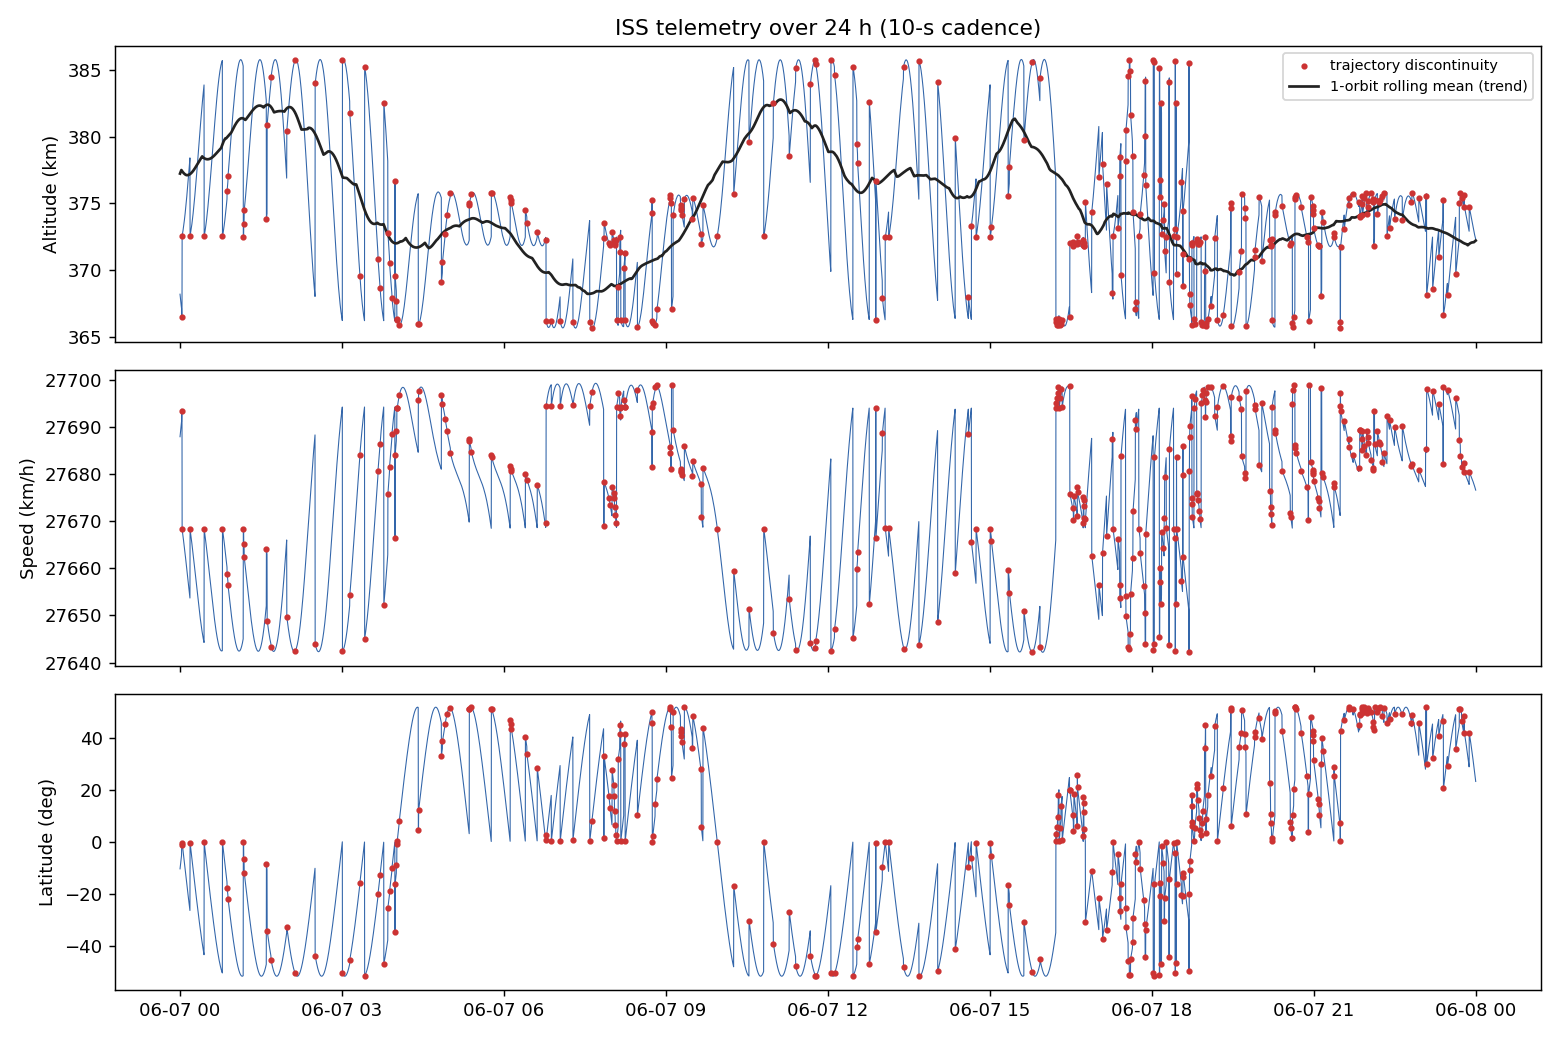

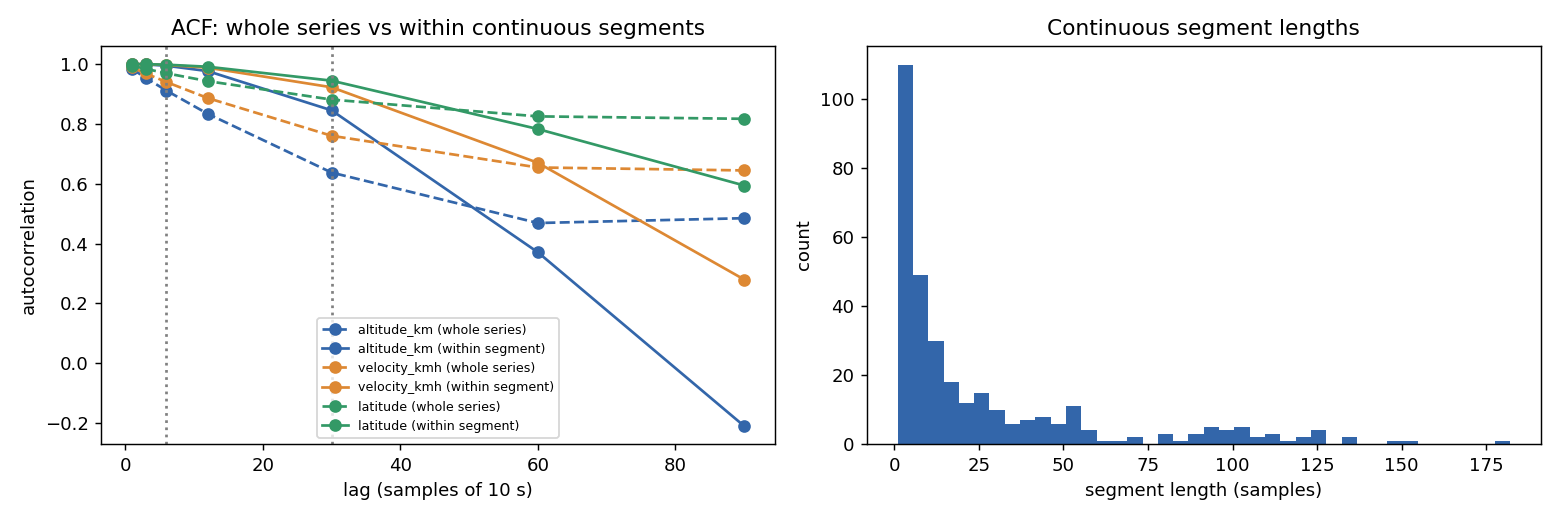

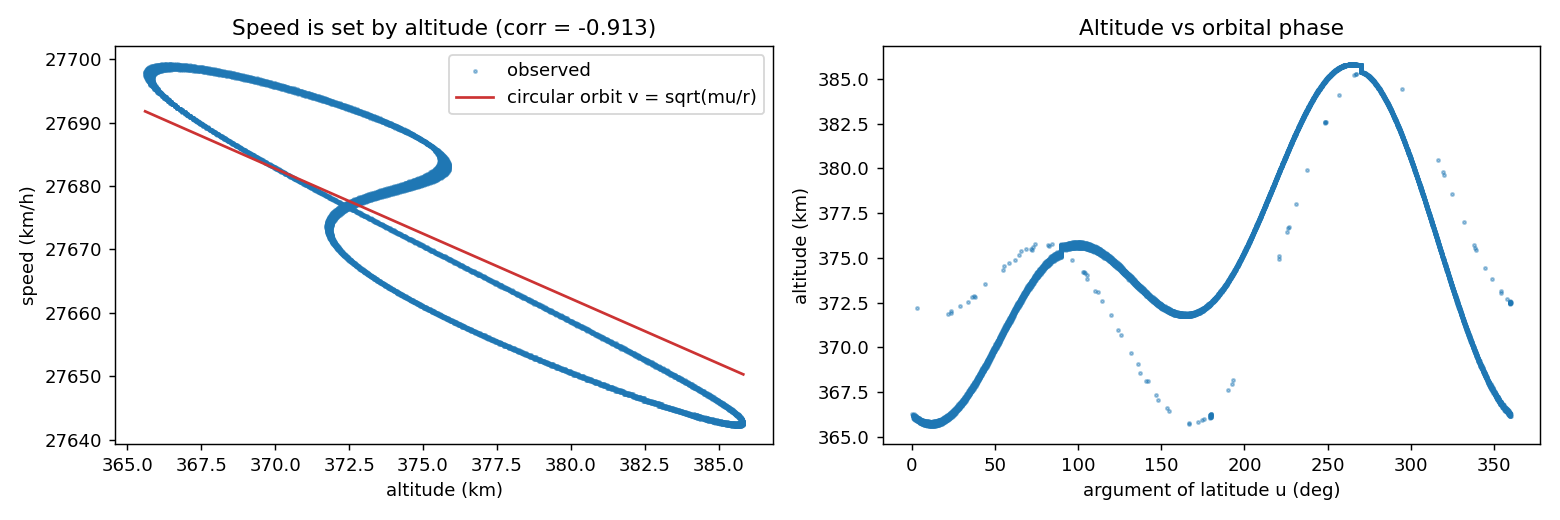

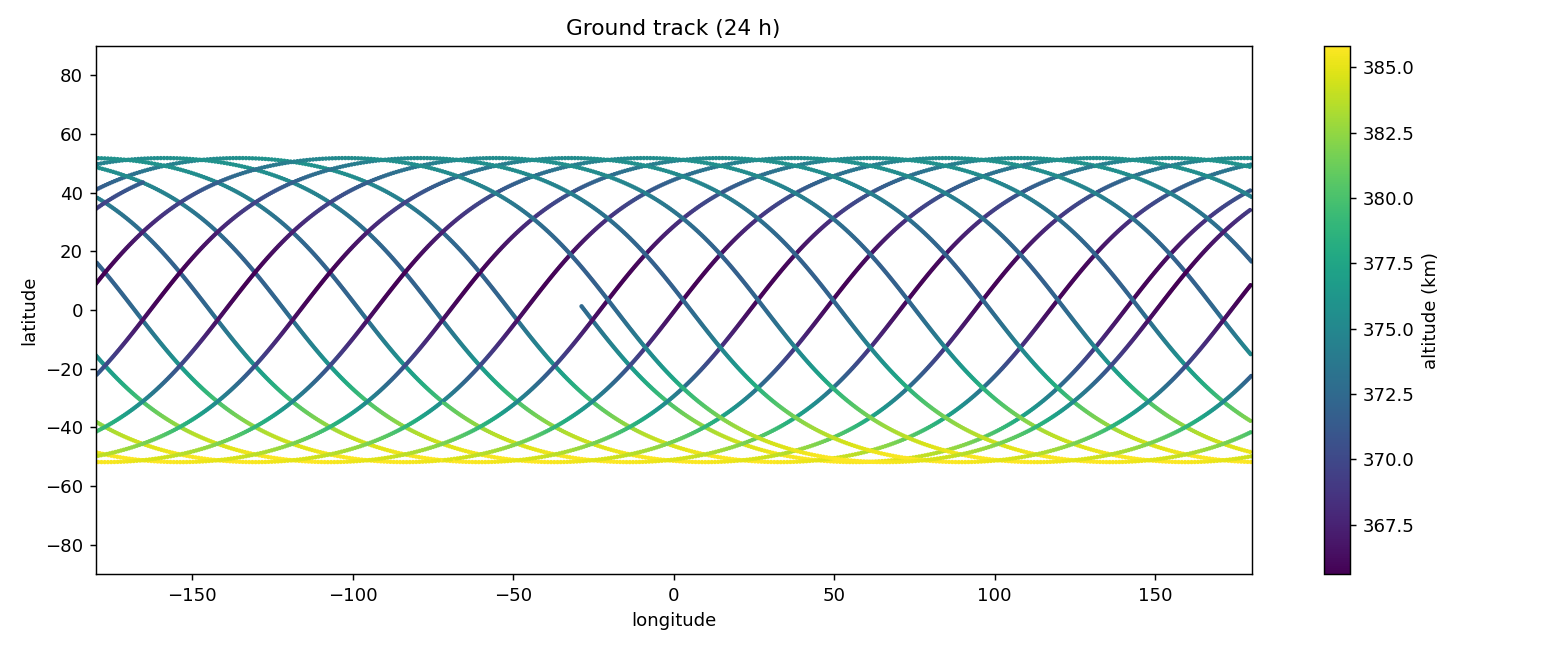

In [6]:
from sources.time_series_analysis import run_analysis
ts = run_analysis()
print(json.dumps({k: ts[k] for k in ["natural_discontinuities","segments","corr_altitude_speed","orbital_period_latitude_phase",
      "orbital_period_vis_viva","naive_fft_dominant_period_min","altitude_trend_km_per_day","window_justification"]}, indent=2))
for f in ["ts_overview","acf_segments","orbit_physics","ground_track"]:
    display(Image(filename=str(FIGURES_DIR / f"{f}.png")))

## 6. Anomaly Detection

Anomaly detection - test split
                      precision  recall      f1  roc_auc  pr_auc  false_alarms_per_hour
method                                                                                 
raw_iforest_baseline     0.1484  0.1963  0.1690   0.5432  0.1855                 33.395
rule                     1.0000  1.0000  1.0000   1.0000  1.0000                  0.000
iforest                  0.7634  0.9953  0.8641   0.9970  0.9661                  9.145
hybrid                   0.7643  1.0000  0.8664   0.9999  0.9993                  9.145

Recall by anomaly type (primary method = rule):
                          count  detected  recall
truth_type                                       
altitude_spike               15        15     1.0
position_glitch               2         2     1.0
stuck_sensor                 16        16     1.0
trajectory_discontinuity    172       172     1.0
velocity_spike                9         9     1.0

Noise sensitivity (test F1):
method      

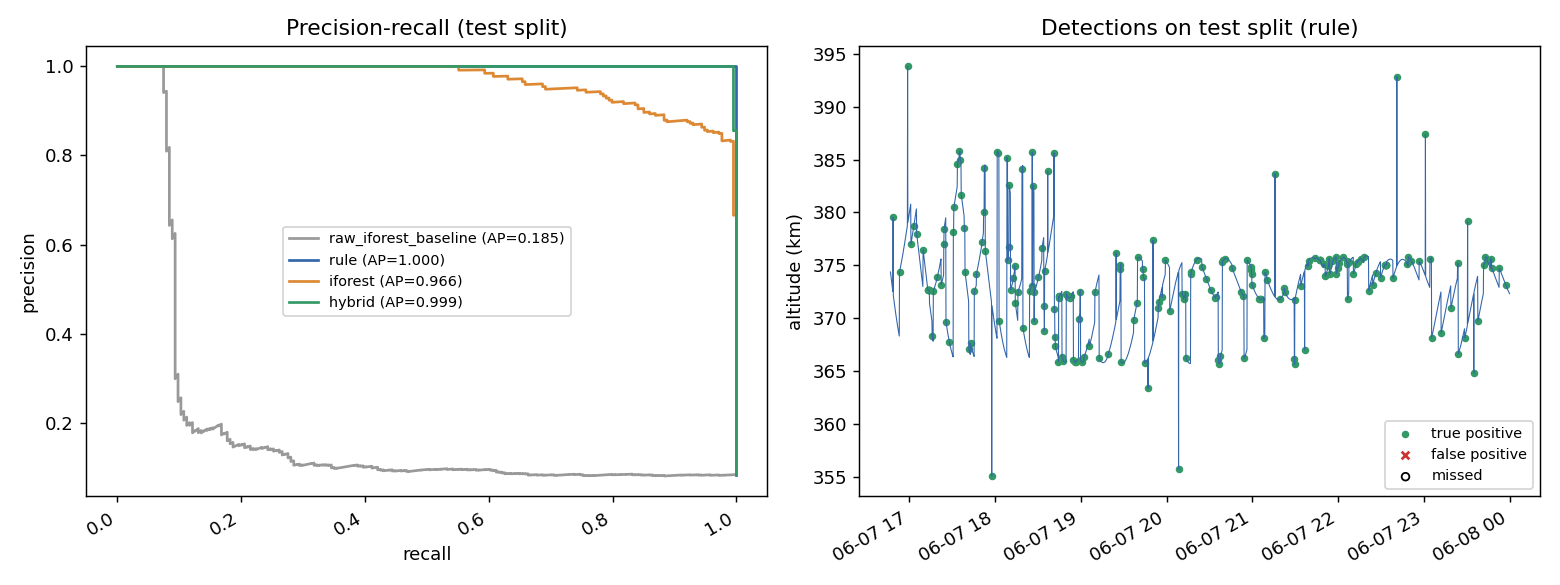

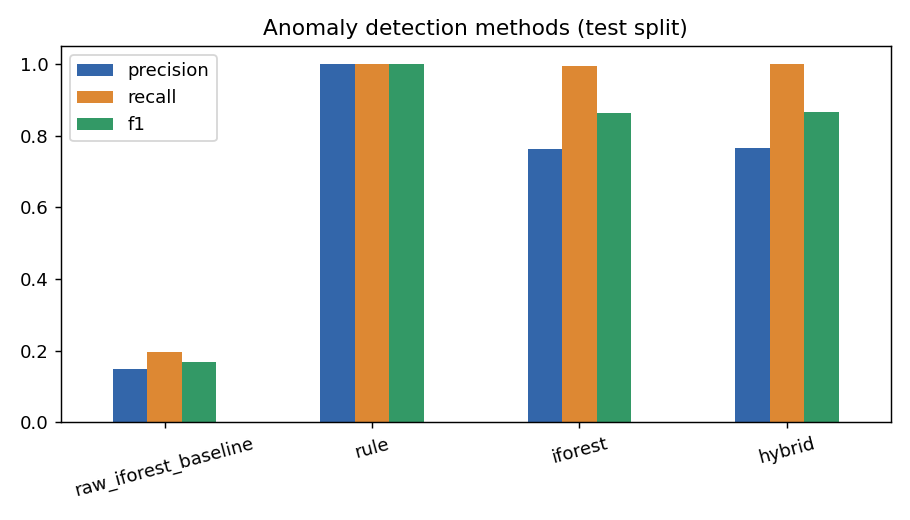

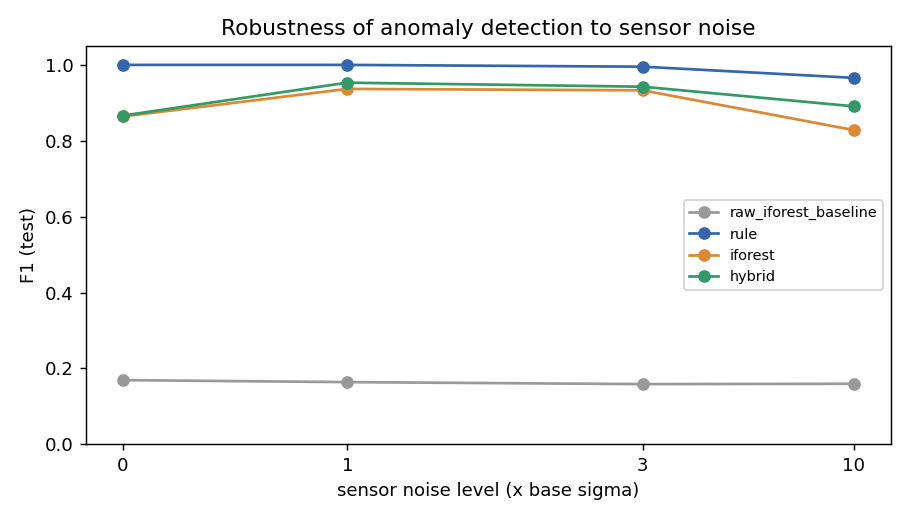

In [7]:
from sources.train_models import run_anomaly_experiment, run_noise_sensitivity
anom = run_anomaly_experiment()
noise = run_noise_sensitivity()
display(Image(filename=str(FIGURES_DIR / "anomaly_evaluation.png")))
display(Image(filename=str(FIGURES_DIR / "anomaly_methods.png")))
display(Image(filename=str(FIGURES_DIR / "anomaly_noise_sensitivity.png")))

## 7. Machine Learning


Forecasting - test split (models refit on train+validation)
 horizon_sec             model    n  n_train  val_pos_mae_km  pos_mae_km  pos_rmse_km  pos_p95_km  alt_mae_km  vel_mae_kmh
          10       persistence 1669     5149         69.7208     69.8150      69.8153     70.1549      0.0778       0.1757
          10 constant_velocity 1669     5149          0.0523      0.0538       0.0588      0.0822      0.0050       0.0055
          10             ridge 1669     5149          0.0177      0.0088       0.0093      0.0129      0.0029       0.0031
          10 gradient_boosting 1669     5149          1.4120      0.2444       0.2902      0.5296      0.0034       0.0036
          60       persistence 1266     4670        418.2750    418.8857     418.8873    420.8793      0.4706       1.0410
          60 constant_velocity 1266     4670          1.1221      1.1444       1.2389      1.7258      0.0368       0.0489
          60             ridge 1266     4670          0.2081      0.1015      

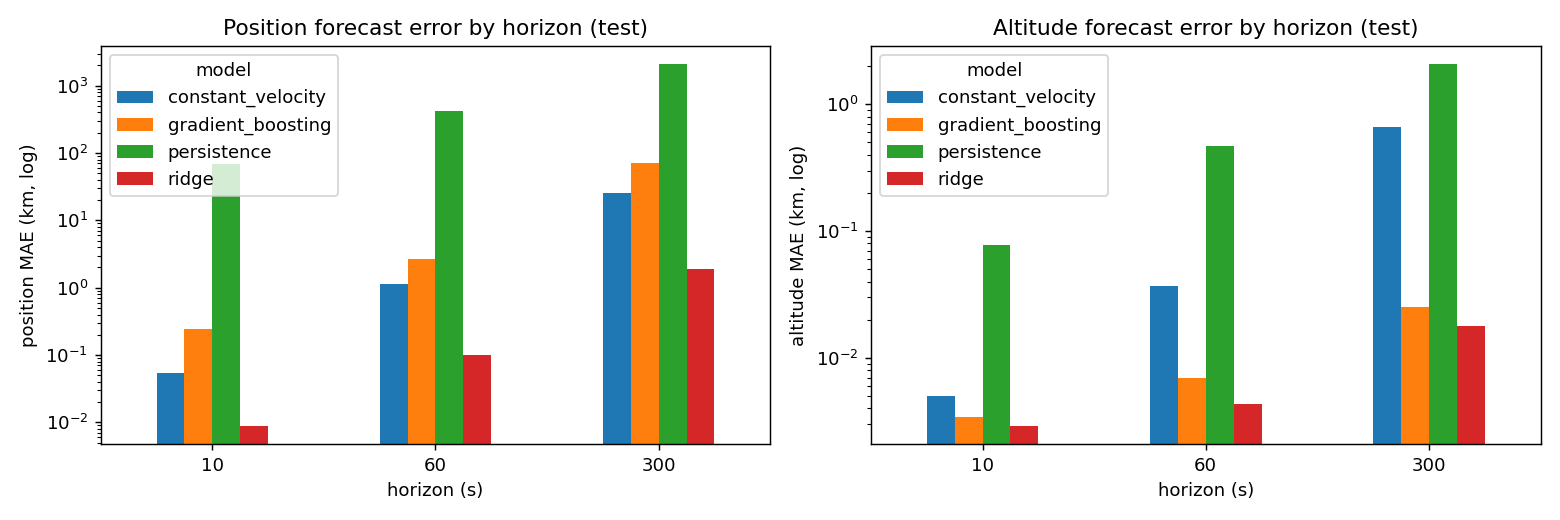

In [8]:
from sources.train_models import run_forecast_experiment
fc = run_forecast_experiment()
display(Image(filename=str(FIGURES_DIR / "forecast_evaluation.png")))

## 8. Distributed Processing

In [9]:
from sources.config import DATA_DIR
from sources.stream_processor import run_pipeline
broker_summary = run_pipeline(source="broker", backend="auto", batch_size=100,
                              db_path=DATA_DIR / "iss_broker_run.db", verbose=False)
print("backend:", broker_summary["config"]["backend"], "| events:", broker_summary["events_out"],
      "| per-partition:", broker_summary["config"].get("partition_sizes"), "| throughput:", broker_summary["throughput_eps"])

backend: memory | events: 8597 | per-partition: {0: 8683} | throughput: 2299.3


workers=1: 14.44s  2406 events/s  identical=True
workers=2: 10.57s  3286 events/s  identical=True
workers=4: 11.42s  3042 events/s  identical=True
 workers  wall_sec  throughput_eps  rows_written  results_identical_to_1_worker  speedup  efficiency  cpu_cores_available
       1    14.438          2405.6         34388                           True     1.00        1.00                   12
       2    10.569          3286.2         34388                           True     1.37        0.68                   12
       4    11.416          3042.4         34388                           True     1.26        0.32                   12


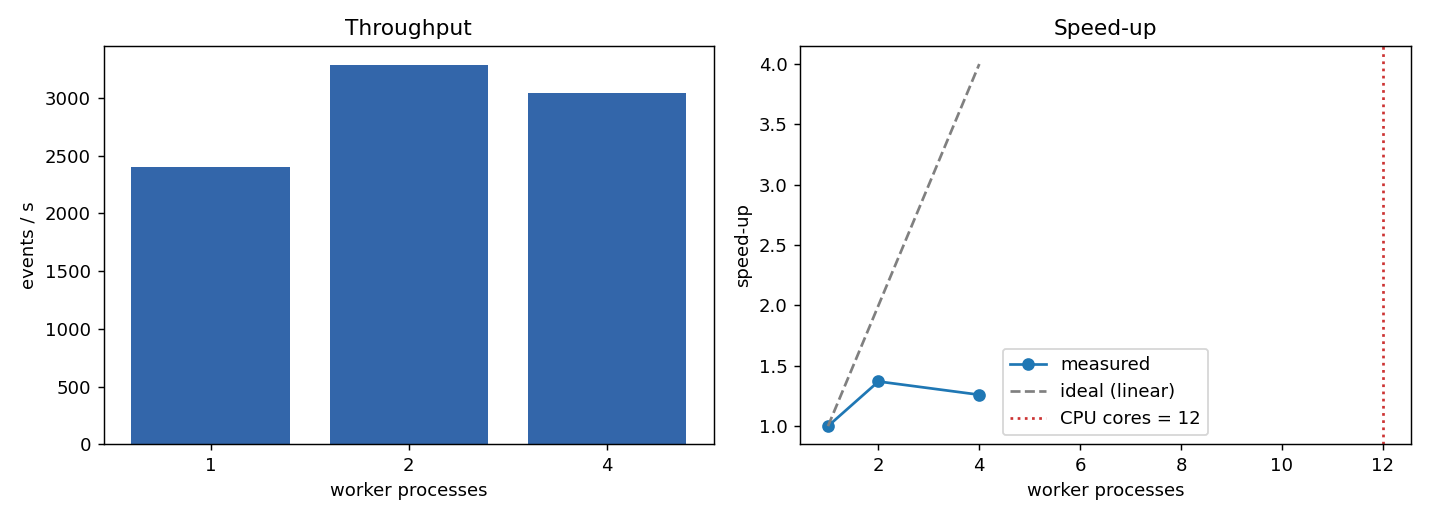

In [10]:
from sources.distributed_pipeline import scaling_experiment
scaling = scaling_experiment(n_satellites=4, worker_counts=(1, 2, 4), events_per_sat=8640)
display(Image(filename=str(FIGURES_DIR / "distributed_scaling.png")))

In [11]:
try:
    from sources.partD import create_iss_spark_session, run_spark_batch_window_aggregation
    spark = create_iss_spark_session()
    tumbling_sdf, sliding_sdf, stats = run_spark_batch_window_aggregation(spark=spark)
    print(stats); tumbling_sdf.show(5, truncate=False)
    spark.stop()
except Exception as e:
    print("Spark not available - skipped:", e)

{'valid_events': 8640, 'discontinuities': 285, 'median_step_km': 69.78973266215114}
+-------------------+-------------------+----------+-----------+---------------+---------------+----------------+------------------+---------------+
|window_start       |window_end         |hemisphere|event_count|avg_altitude_km|std_altitude_km|avg_velocity_kmh|velocity_range_kmh|discontinuities|
+-------------------+-------------------+----------+-----------+---------------+---------------+----------------+------------------+---------------+
|2025-06-07 00:00:00|2025-06-07 00:01:00|Southern  |6          |367.89         |0.2128         |27688.728       |1.66              |0              |
|2025-06-07 00:01:00|2025-06-07 00:02:00|Southern  |6          |367.17         |0.3592         |27690.945       |3.38              |1              |
|2025-06-07 00:02:00|2025-06-07 00:03:00|Southern  |6          |370.577        |3.2359         |27676.448       |26.24             |1              |
|2025-06-07 00:03:00|2

## 9. Performance Evaluation

1) micro-batch sweep
  batch=   1:      109 ev/s  p95=33.52 ms  bottleneck=3_anomaly_detection
  batch=  10:      760 ev/s  p95=26.99 ms  bottleneck=3_anomaly_detection
  batch=  50:     1662 ev/s  p95=58.58 ms  bottleneck=3_anomaly_detection
  batch= 200:     2794 ev/s  p95=97.41 ms  bottleneck=2_features
  batch= 500:     3093 ev/s  p95=173.85 ms  bottleneck=2_features
2) rate-controlled load
  rate=  100: achieved      99 ev/s  p50=60.2 ms  p99=93.7 ms
  rate=  500: achieved     490 ev/s  p50=49.2 ms  p99=100.1 ms
  rate= 1000: achieved     978 ev/s  p50=52.6 ms  p99=99.2 ms
  rate= 2000: achieved    1946 ev/s  p50=67.4 ms  p99=154.6 ms
  rate= 4000: achieved    3030 ev/s  p50=319.2 ms  p99=705.4 ms
  rate= 8000: achieved    3086 ev/s  p50=821.9 ms  p99=1472.9 ms
3) storage pattern
   {'per_event_connect_commit': {'events': 1000, 'sec': 6.5702, 'us_per_event': 6570.2}, 'single_connection_batched': {'events': 1000, 'sec': 0.0228, 'us_per_event': 22.8}, 'speedup': 288.2}

Batch sweep:

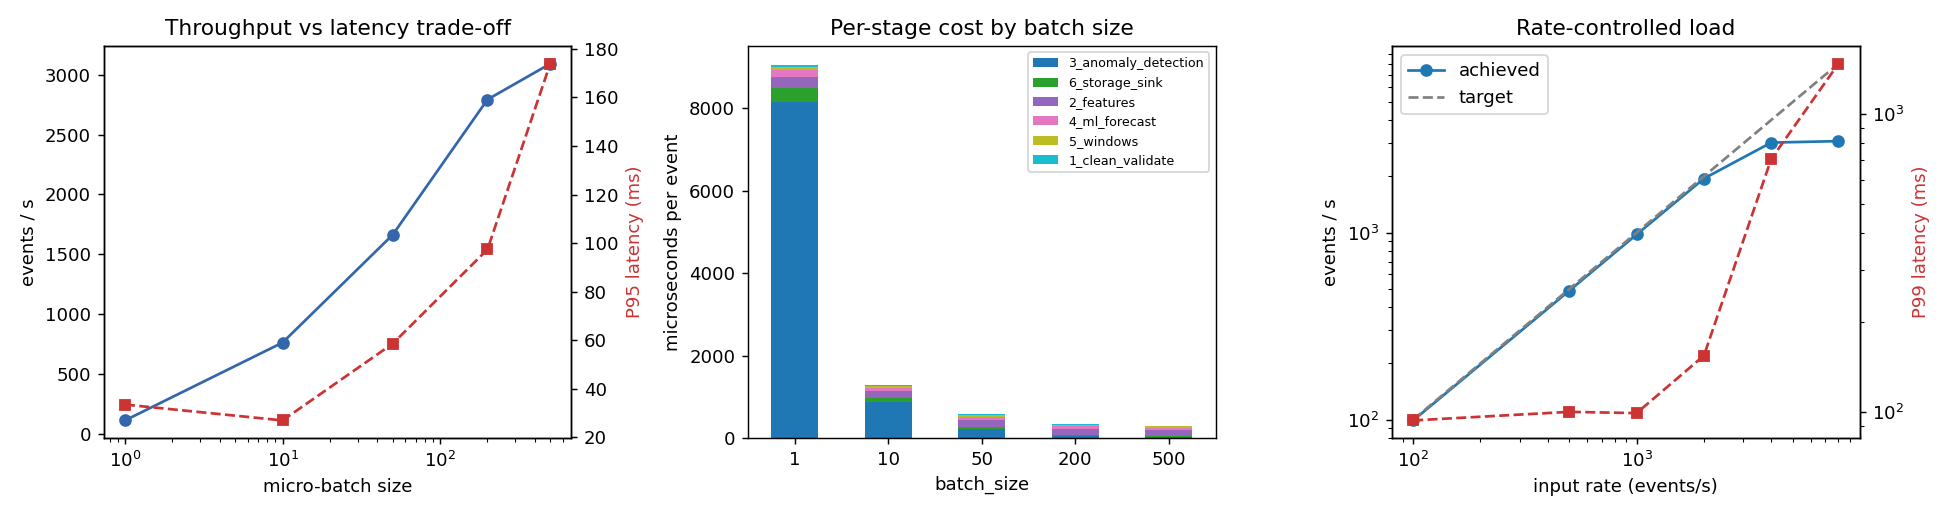

In [12]:
from sources.benchmark_test import run_all as run_benchmark
bench = run_benchmark(3000)
display(Image(filename=str(FIGURES_DIR / "benchmark.png")))

## 10. Data Persistence

In [13]:
from sources.stream_processor import run_pipeline
stream_summary = run_pipeline(source="csv", batch_size=50, reset_db=True)

  processed 1000 events ...
  processed 2000 events ...
  processed 3000 events ...
  processed 4000 events ...
  processed 5000 events ...
  processed 6000 events ...
  processed 7000 events ...
  processed 8000 events ...
{
  "events_in": 8683,
  "events_out": 8597,
  "throughput_eps": 1970.1,
  "latency_ms": {
    "mean": 25.597,
    "p50": 23.33,
    "p95": 45.62,
    "p99": 53.942,
    "max": 117.712
  },
  "cleaning": {
    "received": 8683,
    "valid": 8597,
    "released": 8597,
    "duplicates": 43,
    "late_dropped": 9,
    "reordered": 44,
    "rejected": {
      "duplicate": 43,
      "null_value": 6,
      "missing_field": 17,
      "late_event": 9,
      "out_of_range": 11
    }
  },
  "online_detection_test_period": {
    "precision": 1.0,
    "recall": 1.0,
    "f1": 1.0,
    "tp": 214,
    "fp": 0,
    "fn": 0,
    "tn": 2359,
    "roc_auc": 1.0,
    "pr_auc": 1.0
  },
  "online_forecast": {
    "horizon_sec": 60,
    "scored": 4582,
    "pos_mae_km": 0.0991,
    "po

In [14]:
from sources.database import ISSDatabaseSink
db = ISSDatabaseSink()
print(db.table_counts())
display(db.query("SELECT timestamp, event_id, reason, rule_score, altitude_km, velocity_kmh, truth_type FROM anomalies ORDER BY timestamp LIMIT 10"))
display(db.query("SELECT status, COUNT(*) n, ROUND(AVG(pos_error_km),4) mae_km FROM predictions GROUP BY status"))
display(db.query("SELECT reason, COUNT(*) n FROM rejected_events GROUP BY reason"))

{'raw_events': 8683, 'telemetry': 8597, 'window_metrics': 2875, 'anomalies': 544, 'predictions': 5841, 'rejected_events': 86, 'pipeline_runs': 1}


,timestamp,event_id,reason,rule_score,altitude_km,velocity_kmh,truth_type
0,2025-06-07T00:01:50Z,ISS-25544-000012,position,9821.787,366.49,27693.25,trajectory_discontinuity
1,2025-06-07T00:02:20Z,ISS-25544-000015,position,218737.743,372.57,27668.22,trajectory_discontinuity
2,2025-06-07T00:04:20Z,ISS-25544-000027,position,18303.371,373.46,27665.19,position_glitch
3,2025-06-07T00:11:10Z,ISS-25544-000068,position,111748.203,372.55,27668.27,trajectory_discontinuity
4,2025-06-07T00:18:20Z,ISS-25544-000111,speed,19366.653,377.10,27943.48,velocity_spike
5,2025-06-07T00:23:00Z,ISS-25544-000139,speed,5831.647,381.15,27735.07,velocity_spike
6,2025-06-07T00:26:50Z,ISS-25544-000162,position,165299.413,372.54,27668.32,trajectory_discontinuity
7,2025-06-07T00:30:20Z,ISS-25544-000183,speed,4353.838,374.30,27727.37,velocity_spike
8,2025-06-07T00:37:30Z,ISS-25544-000226,position,1392.469,379.98,27650.67,stuck_sensor
9,2025-06-07T00:37:40Z,ISS-25544-000227,position,2786.235,379.98,27650.67,stuck_sensor


,status,n,mae_km
0,invalidated_by_discontinuity,698,NaN
1,scored,4582,0.0991
2,target_missing,26,NaN
3,target_not_comparable,535,NaN


,reason,n
0,duplicate,43
1,late_event,9
2,missing_field,17
3,null_value,6
4,out_of_range,11


## 4. Visualization

The live dashboard is a Streamlit app (`dashboard/app.py`). It reads the SQLite database and refreshes every 2 seconds. Run it in two terminals:

    python -m sources.stream_processor --speedup 20 --batch-size 1
    streamlit run dashboard/app.py

It shows the ground-track map with anomalies and the 60-s forecast, altitude and speed charts, window indicators, the alert log, forecast errors and data-quality rejections.